# Tugas Besar 2 IF3170 Inteligensi Artifisial

Prediksi pembatalan pemesanan menggunakan Decision Tree ID3.

## Group 31 - Kelompok Dadakan

- Farrel Limjaya (13524046)
- Raymond Jonathan Dwi Putra Julianto (13524059)
- Reynard Anderson Wijaya (13524111)
- Fauzan Mohamad Abdul Ghani (13524113)
- Hasna Nurul Alimah (11424061)

## Table of Contents

1. [Introduction](#1)
2. [Initialization](#2)
3. [Data Understanding](#3)
4. [Training and Validation Split](#4)
5. [Data Preparation](#5)
6. [Preparation Pipeline](#6)
7. [Modeling and Validation](#7)
8. [Comparison with scikit-learn](#8)
9. [Saving and Loading Models](#9)
10. [Kaggle Submission](#10)

---

# Introduction <a name="1"></a>

---

Pembatalan dapat menyisakan kamar kosong. Prediksi membantu penginapan merencanakan pemesanan.

## Overview

Setiap baris merupakan satu pemesanan dengan informasi tamu, masa inap, kamar, harga, dan riwayat.

## Aim

Prediksi `is_canceled` menggunakan ID3 from scratch dan bandingkan dengan scikit-learn.

## Metric

Kaggle menggunakan Macro F1: rata-rata F1 kelas tidak batal (0) dan batal (1). Public leaderboard memakai sekitar 30% data test; private leaderboard memakai sisanya.

## Dataset

`train.csv` memiliki label `is_canceled`; `test.csv` digunakan untuk prediksi. Submission berisi `id` dan `is_canceled`.

| Kolom | Arti |
|---|---|
| `id` | Identitas unik pemesanan; disimpan sebagai teks. |
| `num_adults`, `num_children` | Jumlah tamu dewasa dan anak. |
| `weekend_nights`, `weekday_nights` | Jumlah malam akhir pekan dan hari kerja. |
| `meal_package` | Paket makanan. |
| `needs_parking` | Kebutuhan parkir: 0 atau 1. |
| `room_category` | Jenis kamar; huruf A-G tidak menunjukkan urutan kualitas. |
| `days_before_arrival` | Jarak hari dari pemesanan ke kedatangan. |
| `arrival_year`, `arrival_month`, `arrival_day` | Tanggal kedatangan. |
| `booking_channel` | Saluran pemesanan. |
| `is_returning_guest` | Pernah menginap sebelumnya: 0 atau 1. |
| `prior_cancellations`, `prior_completed_bookings` | Jumlah pemesanan sebelumnya yang dibatalkan dan tidak dibatalkan. |
| `nightly_rate_idr` | Harga rata-rata per kamar per malam; nol biasanya berarti gratis. |
| `special_requests` | Jumlah permintaan khusus. |
| `is_canceled` | Target pembatalan: 0 atau 1. |

## Approach

Periksa dan bagi data, lakukan preprocessing dari data training, lalu latih dan evaluasi ID3.

---

# Initialization <a name="2"></a>

---

Pustaka yang diperlukan: NumPy, pandas, scikit-learn, dan Matplotlib.

## Environment Setup

Jalankan instalasi jika pustaka belum tersedia.

In [1]:
# %pip install numpy pandas "scikit-learn>=1.2" matplotlib

## Import Libraries

In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

## Settings

Path dicari dari folder notebook atau proyek.

In [3]:
root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data" / "train.csv").exists() and (p / "src").exists()
)
DATA_DIR = root / "data"
SEED = 42
sys.path.insert(0, str(root / "src"))

from preprocessing.preprocessing import create_preprocessor

## Seed Everything

Seed digunakan agar pembagian data dapat diulang.

In [4]:
np.random.seed(SEED)

## Load Dataset

`id` dibaca sebagai teks dan tidak digunakan sebagai fitur.

In [5]:
train_df = pd.read_csv(DATA_DIR / "train.csv", dtype={"id": str})
test_df = pd.read_csv(DATA_DIR / "test.csv", dtype={"id": str})
submission_example = pd.read_csv(DATA_DIR / "sample_submission.csv", dtype={"id": str})

assert "is_canceled" in train_df and "is_canceled" not in test_df
assert train_df.drop(columns="is_canceled").columns.equals(test_df.columns)
assert submission_example["id"].equals(test_df["id"])
print(f"Train: {train_df.shape} | Test: {test_df.shape}")
display(train_df.head())

Train: (27373, 19) | Test: (6844, 18)


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


---

# Data Understanding (Optional) <a name="3"></a>

---

Statistik preprocessing dihitung setelah data training dan validasi dipisahkan.

## Describe Data

Kolom bilangan bulat dapat terbaca sebagai float jika ada nilai kosong.

In [6]:
ringkasan = pd.DataFrame({
    "tipe": train_df.dtypes.astype(str),
    "nilai_unik": train_df.nunique(),
    "kosong_train": train_df.isna().sum(),
    "persen_kosong_train": train_df.isna().mean().mul(100).round(2),
})
display(ringkasan)
display(train_df.describe().round(2))

,tipe,nilai_unik,kosong_train,persen_kosong_train
id,str,27373,0,0.00
num_adults,float64,5,809,2.96
num_children,float64,6,3035,11.09
weekend_nights,int64,8,0,0.00
weekday_nights,int64,18,0,0.00
meal_package,str,4,1760,6.43
needs_parking,float64,2,1082,3.95
room_category,str,7,1002,3.66
days_before_arrival,float64,407,1123,4.10
arrival_year,int64,2,0,0.00


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.00,24338.00,27373.00,27373.00,26291.00,26250.00,27373.00,27373.00,27373.00,27373.00,27373.00,27373.00,25335.00,24873.00,27373.00
mean,1.85,0.12,0.81,2.21,0.03,85.38,2023.82,7.40,15.54,0.03,0.02,0.14,1716979.55,0.67,0.33
std,0.52,0.43,0.88,1.42,0.17,85.97,0.38,3.07,8.77,0.16,0.36,1.69,587936.77,0.80,0.47
min,0.00,0.00,0.00,0.00,0.00,0.00,2023.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2.00,0.00,0.00,1.00,0.00,17.00,2024.00,5.00,8.00,0.00,0.00,0.00,1338000.00,0.00,0.00
50%,2.00,0.00,1.00,2.00,0.00,58.00,2024.00,8.00,16.00,0.00,0.00,0.00,1644000.00,0.00,0.00
75%,2.00,0.00,2.00,3.00,0.00,126.00,2024.00,10.00,23.00,0.00,0.00,0.00,2019000.00,1.00,1.00
max,4.00,10.00,7.00,17.00,1.00,448.00,2024.00,12.00,31.00,1.00,13.00,58.00,9165000.00,5.00,1.00


## Explore Data

Periksa distribusi label, jarak pemesanan, harga, dan kategori.

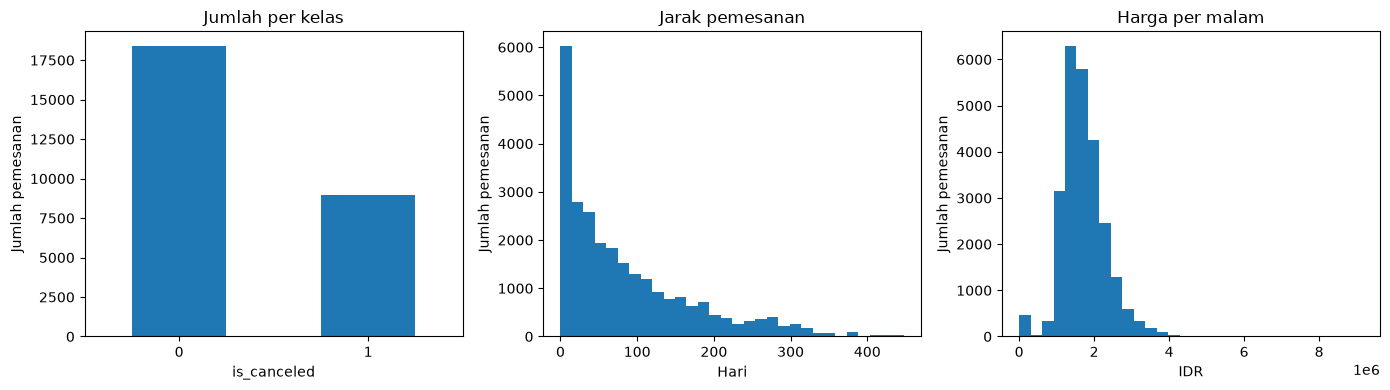

,jumlah
meal_package,
Breakfast,19654
Room Only,3713
Half Board,2242
NaN,1760
Full Board,4


,jumlah
room_category,
Type B,20447
Type G,4396
NaN,1002
Type A,699
Type D,514
Type C,189
Type F,119
Type E,7


,jumlah
booking_channel,
Online Travel Agent,17511
Offline Agent,7960
Corporate,1513
Complimentary,301
Airline,88


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
train_df["is_canceled"].value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Jumlah per kelas", xlabel="is_canceled", ylabel="Jumlah pemesanan")
train_df["days_before_arrival"].plot.hist(bins=30, ax=axes[1])
axes[1].set(title="Jarak pemesanan", xlabel="Hari", ylabel="Jumlah pemesanan")
train_df["nightly_rate_idr"].plot.hist(bins=30, ax=axes[2])
axes[2].set(title="Harga per malam", xlabel="IDR", ylabel="Jumlah pemesanan")
plt.tight_layout()
plt.show()

for kolom in ["meal_package", "room_category", "booking_channel"]:
    display(train_df[kolom].value_counts(dropna=False).rename("jumlah").to_frame())

## Verify Data Quality

Periksa nilai kosong, identitas, dan baris duplikat.

In [8]:
kualitas = []
for nama, data in [("train", train_df), ("test", test_df)]:
    assert data["id"].notna().all() and data["id"].is_unique, f"Periksa ID pada {nama}"
    kualitas.append({
        "data": nama,
        "baris": len(data),
        "baris_dengan_nilai_kosong": data.isna().any(axis=1).sum(),
        "duplikat_seluruh_kolom": data.duplicated().sum(),
        "fitur_sama_id_berbeda": data.drop(columns=["id", "is_canceled"], errors="ignore").duplicated().sum(),
    })
assert train_df["is_canceled"].isin([0, 1]).all(), "Target harus 0 atau 1 tanpa nilai kosong"
display(pd.DataFrame(kualitas).set_index("data"))

,baris,baris_dengan_nilai_kosong,duplikat_seluruh_kolom,fitur_sama_id_berbeda
data,,,,
train,27373,10737,0,66
test,6844,2669,0,3


---

# Training and Validation Split <a name="4"></a>

---

Sebanyak 80% data train digunakan untuk training dan 20% untuk validasi dengan stratifikasi. Data test tetap terpisah.

In [9]:
train_set, val_set = train_test_split(
    train_df, test_size=0.2, random_state=SEED, stratify=train_df["is_canceled"]
)
assert set(train_set["id"]).isdisjoint(val_set["id"])
assert len(train_set) + len(val_set) == len(train_df)
print("Training:", len(train_set), "| Validasi:", len(val_set))

Training: 21898 | Validasi: 5475


## Heatmap Korelasi

Korelasi Pearson dihitung dari bagian training. Nilai mendekati 1 atau -1 menunjukkan hubungan linear yang lebih kuat; korelasi tidak membuktikan sebab-akibat.

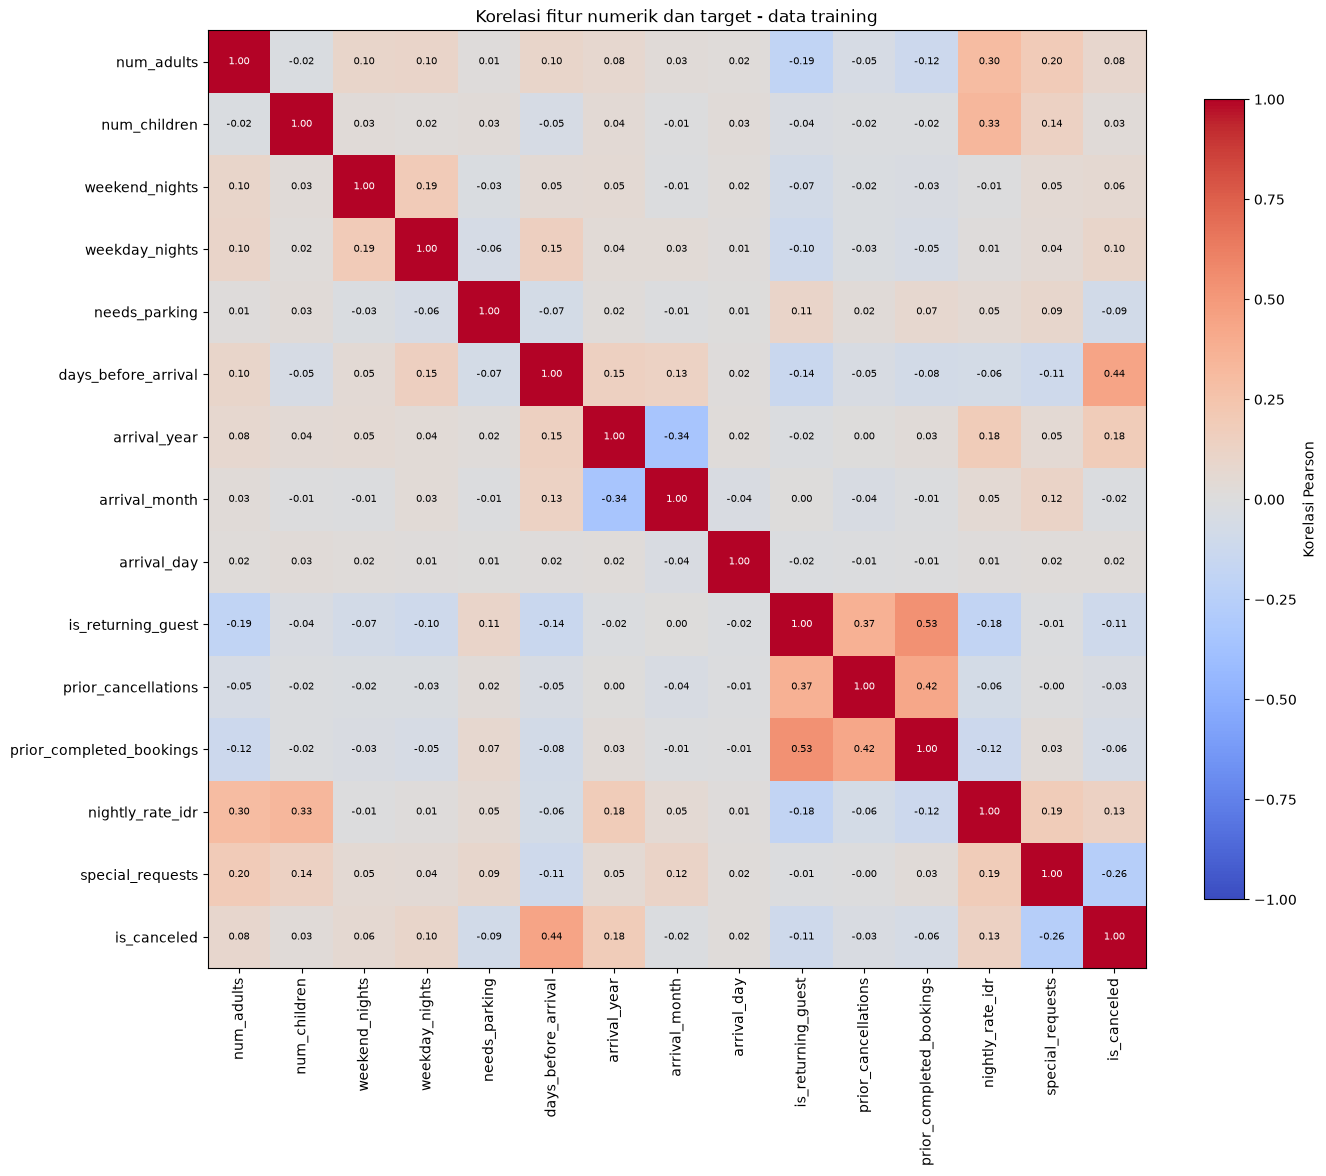

In [10]:
korelasi = train_set.drop(columns="id").corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(14, 12))
gambar = ax.imshow(korelasi, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(korelasi.columns)), korelasi.columns, rotation=90)
ax.set_yticks(range(len(korelasi.index)), korelasi.index)
ax.set_title("Korelasi fitur numerik dan target - data training")
for baris in range(len(korelasi)):
    for kolom in range(len(korelasi.columns)):
        nilai = korelasi.iloc[baris, kolom]
        ax.text(kolom, baris, f"{nilai:.2f}", ha="center", va="center",
                color="white" if abs(nilai) > 0.55 else "black", fontsize=7)
fig.colorbar(gambar, ax=ax, label="Korelasi Pearson", shrink=0.8)
plt.tight_layout()
plt.show()

---

# Data Preparation <a name="5"></a>

---

Preprocessing menggunakan scikit-learn; model ID3 dibuat from scratch.

## Select Data

Gunakan 17 fitur selain `id` dan target.

In [11]:
X_train = train_set.drop(columns=["id", "is_canceled"])
y_train = train_set["is_canceled"].copy()
X_valid = val_set.drop(columns=["id", "is_canceled"])
y_valid = val_set["is_canceled"].copy()
X_test = test_df.drop(columns="id")
id_test = test_df["id"].copy()

kolom_numerik = X_train.select_dtypes(include="number").columns.tolist()
kolom_kategori = X_train.select_dtypes(exclude="number").columns.tolist()
assert X_train.columns.equals(X_valid.columns) and X_train.columns.equals(X_test.columns)
print("Numerik:", kolom_numerik)
print("Kategori:", kolom_kategori)

Numerik: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
Kategori: ['meal_package', 'room_category', 'booking_channel']


## Clean Data

Nilai kosong diisi tanpa menghapus baris.

### Missing Values

Nilai numerik diisi median dan kategori diisi modus dari training. Nilai kosong tidak selalu berarti nol.

In [12]:
nilai_pengisi = pd.concat([
    X_train[kolom_numerik].median(),
    X_train[kolom_kategori].mode().iloc[0],
]).reindex(X_train.columns)
assert nilai_pengisi.notna().all(), "Ada kolom training yang seluruh nilainya kosong"
assert nilai_pengisi[["needs_parking", "is_returning_guest"]].isin([0, 1]).all()

display(pd.DataFrame({
    "kosong_training": X_train.isna().sum(),
    "kosong_validasi": X_valid.isna().sum(),
    "kosong_test": X_test.isna().sum(),
    "nilai_pengisi_training": nilai_pengisi,
}))

,kosong_training,kosong_validasi,kosong_test,nilai_pengisi_training
num_adults,636,173,180,2.0
num_children,2426,609,747,0.0
weekend_nights,0,0,0,1.0
weekday_nights,0,0,0,2.0
meal_package,1403,357,442,Breakfast
needs_parking,885,197,247,0.0
room_category,810,192,242,Type B
days_before_arrival,877,246,290,57.0
arrival_year,0,0,0,2024.0
arrival_month,0,0,0,8.0


### Duplicates

Tidak ditemukan ID atau baris lengkap yang duplikat. Fitur yang sama dengan ID berbeda dipertahankan karena dapat merupakan pemesanan terpisah.

In [13]:
fitur = X_train.columns.tolist()
print("Duplikat lengkap training:", train_set.duplicated().sum())
print("Duplikat lengkap validasi:", val_set.duplicated().sum())
print("Fitur sama dalam training:", X_train.duplicated().sum())
print("Fitur sama dalam validasi:", X_valid.duplicated().sum())
contoh_serupa = train_set.loc[train_set.duplicated(subset=fitur, keep=False)]
display(contoh_serupa.head(6))

Duplikat lengkap training: 0
Duplikat lengkap validasi: 0
Fitur sama dalam training: 41
Fitur sama dalam validasi: 4


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
3315,3d8aaa46,2.0,0.0,2,0,Half Board,0.0,Type B,388.0,2024,10,22,Offline Agent,0,0,0,NaN,1.0,1
4140,a7e0ef46,1.0,0.0,0,2,Breakfast,0.0,Type B,156.0,2024,1,19,Offline Agent,0,0,0,1153000.0,0.0,0
21228,a84fd29c,2.0,0.0,0,2,Half Board,0.0,Type B,103.0,2023,10,16,Offline Agent,0,0,0,NaN,0.0,1
22671,3f675e87,2.0,0.0,0,1,Breakfast,0.0,Type B,NaN,2024,6,7,Offline Agent,0,0,0,NaN,0.0,0
7033,5c701cb0,1.0,0.0,2,4,Breakfast,0.0,Type B,247.0,2024,7,5,Offline Agent,0,0,0,NaN,0.0,1
19786,0f0a0e55,2.0,0.0,0,2,Half Board,0.0,Type B,43.0,2023,8,14,Offline Agent,0,0,0,NaN,0.0,0


### Outliers

IQR menandai nilai ekstrem tanpa menghapusnya. Harga nol biasanya berarti gratis; jumlah malam nol masih perlu klarifikasi.

In [14]:
kolom_tinjau = ["nightly_rate_idr", "days_before_arrival", "weekend_nights", "weekday_nights"]
q1 = X_train[kolom_tinjau].quantile(0.25)
q3 = X_train[kolom_tinjau].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr
display(pd.DataFrame({
    "batas_bawah": batas_bawah,
    "batas_atas": batas_atas,
    "jumlah_di_luar_batas": (
        X_train[kolom_tinjau].lt(batas_bawah) | X_train[kolom_tinjau].gt(batas_atas)
    ).sum(),
}))

for nama, data in [("training", X_train), ("validasi", X_valid), ("test", X_test)]:
    print(nama, "| harga nol:", data["nightly_rate_idr"].eq(0).sum(),
          "| total malam nol:", (data["weekend_nights"] + data["weekday_nights"]).eq(0).sum())

,batas_bawah,batas_atas,jumlah_di_luar_batas
nightly_rate_idr,314500.0,3046500.0,889
days_before_arrival,-145.0,287.0,755
weekend_nights,-3.0,5.0,13
weekday_nights,-2.0,6.0,201


training | harga nol: 324 | total malam nol: 49
validasi | harga nol: 89 | total malam nol: 15
test | harga nol: 85 | total malam nol: 9


### Data Errors

Periksa angka, tanggal, nilai biner, dan kategori. Nilai kosong akan diisi pada pipeline.

In [15]:
kategori_valid = {
    "meal_package": ["Room Only", "Breakfast", "Half Board", "Full Board"],
    "room_category": [f"Type {huruf}" for huruf in "ABCDEFG"],
    "booking_channel": ["Online Travel Agent", "Offline Agent", "Corporate", "Airline", "Complimentary"],
}
for nama, data in [("training", X_train), ("validasi", X_valid), ("test", X_test)]:
    angka = data[kolom_numerik]
    assert (angka.isna() | np.isfinite(angka)).all().all(), f"Nilai tak hingga pada {nama}"
    assert (angka.isna() | angka.ge(0)).all().all(), f"Angka negatif pada {nama}"
    assert (angka.isna() | angka.mod(1).eq(0)).all().all(), f"Hitungan pecahan pada {nama}"
    for kolom in ["needs_parking", "is_returning_guest"]:
        assert data[kolom].dropna().isin([0, 1]).all(), f"Nilai biner tidak valid: {nama}, {kolom}"
    for kolom, daftar in kategori_valid.items():
        assert data[kolom].dropna().isin(daftar).all(), f"Kategori tidak valid: {nama}, {kolom}"
    tanggal = pd.to_datetime({
        "year": data["arrival_year"], "month": data["arrival_month"], "day": data["arrival_day"]
    }, errors="coerce")
    assert tanggal.notna().all(), f"Tanggal kosong atau tidak valid pada {nama}"
    print(nama, ": pemeriksaan nilai valid lulus")

training : pemeriksaan nilai valid lulus
validasi : pemeriksaan nilai valid lulus
test : pemeriksaan nilai valid lulus


## Construct Data

### Attribute Construction

Total tamu dan malam hanya diperiksa, belum digunakan sebagai fitur.

In [16]:
ringkasan_pemesanan = pd.DataFrame({
    "total_tamu": X_train["num_adults"] + X_train["num_children"],
    "total_malam": X_train["weekend_nights"] + X_train["weekday_nights"],
})
display(ringkasan_pemesanan.describe().round(2))

,total_tamu,total_malam
count,18908.00,21898.00
mean,1.97,3.02
std,0.67,1.80
min,1.00,0.00
25%,2.00,2.00
50%,2.00,3.00
75%,2.00,4.00
max,12.00,24.00


### Feature Scaling

Pipeline melakukan standardisasi setelah imputasi menggunakan statistik training. Decision Tree umumnya tidak memerlukan standardisasi.

In [17]:
display(X_train[kolom_numerik].agg(["min", "median", "max"]).T)
# Parameter scaler dipelajari saat fit pipeline, bukan dari validasi atau test.

,min,median,max
num_adults,0.0,2.0,4.0
num_children,0.0,0.0,10.0
weekend_nights,0.0,1.0,7.0
weekday_nights,0.0,2.0,17.0
needs_parking,0.0,0.0,1.0
days_before_arrival,0.0,57.0,448.0
arrival_year,2023.0,2024.0,2024.0
arrival_month,1.0,8.0,12.0
arrival_day,1.0,16.0,31.0
is_returning_guest,0.0,0.0,1.0


### Encoding

One-hot encoding mengubah kategori menjadi kolom numerik. Kategori baru pada validasi atau test diabaikan.

In [18]:
for kolom in kolom_kategori:
    print(kolom, ":", sorted(X_train[kolom].dropna().unique().tolist()))

meal_package : ['Breakfast', 'Full Board', 'Half Board', 'Room Only']
room_category : ['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G']
booking_channel : ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']


### Dimensionality Reduction

PCA belum digunakan; semua fitur dipertahankan untuk baseline.

In [19]:
print("Jumlah fitur sebelum encoding:", X_train.shape[1])

Jumlah fitur sebelum encoding: 17


## Class Balance

Distribusi kelas dipertahankan tanpa resampling sebagai baseline.

In [20]:
display(pd.DataFrame({
    "jumlah_training": y_train.value_counts(),
    "proporsi_training": y_train.value_counts(normalize=True),
    "proporsi_validasi": y_valid.value_counts(normalize=True),
}).sort_index().round(4))

,jumlah_training,proporsi_training,proporsi_validasi
is_canceled,,,
0,14723,0.6723,0.6723
1,7175,0.3277,0.3277


## Format Data

Pisahkan fitur dari label dan simpan urutan `id_test` untuk submission.

In [21]:
assert X_train.index.equals(y_train.index)
assert X_valid.index.equals(y_valid.index)
assert id_test.equals(test_df["id"])
assert "id" not in X_train and "is_canceled" not in X_train
print("Bentuk input:", X_train.shape, X_valid.shape, X_test.shape)

Bentuk input: (21898, 17) (5475, 17) (6844, 17)


---

# Preparation Pipeline <a name="6"></a>

---

Pipeline di `src/preprocessing/preprocessing.py` di-fit pada training lalu diterapkan ke validasi dan test. Untuk cross-validation, fit ulang pada setiap training fold. Sebelum submission, fit ulang pada seluruh data train.

In [22]:
preprocessor = create_preprocessor(X_train)
X_train_siap = preprocessor.fit_transform(X_train)
X_valid_siap = preprocessor.transform(X_valid)
X_test_siap = preprocessor.transform(X_test)
nama_fitur = preprocessor.get_feature_names_out()

assert X_train_siap.shape == (len(y_train), len(nama_fitur))
assert X_valid_siap.shape == (len(y_valid), len(nama_fitur))
assert X_test_siap.shape == (len(id_test), len(nama_fitur))
for data in [X_train_siap, X_valid_siap, X_test_siap]:
    assert np.isfinite(data).all(), "Hasil preprocessing masih memiliki NaN atau nilai tak hingga"

imputer = preprocessor.named_transformers_["numerik"].named_steps["imputasi"]
np.testing.assert_allclose(imputer.statistics_, X_train[kolom_numerik].median().to_numpy())
print("Training:", X_train_siap.shape, "| Validasi:", X_valid_siap.shape, "| Test:", X_test_siap.shape)
display(pd.DataFrame(X_train_siap[:5], columns=nama_fitur, index=X_train.index[:5]))

Training:

 (21898, 30) | Validasi: (5475, 30) | Test: (6844, 30)


,numerik__num_adults,numerik__num_children,numerik__weekend_nights,numerik__weekday_nights,numerik__needs_parking,numerik__days_before_arrival,numerik__arrival_year,numerik__arrival_month,numerik__arrival_day,numerik__is_returning_guest,...,kategori__room_category_Type C,kategori__room_category_Type D,kategori__room_category_Type E,kategori__room_category_Type F,kategori__room_category_Type G,kategori__booking_channel_Airline,kategori__booking_channel_Complimentary,kategori__booking_channel_Corporate,kategori__booking_channel_Offline Agent,kategori__booking_channel_Online Travel Agent
3315,0.290096,-0.257497,1.350452,-1.547794,-0.174069,3.605815,0.469489,0.846720,0.736343,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
9891,0.290096,-0.257497,0.207963,-0.139258,-0.174069,2.633313,0.469489,1.171684,-1.429894,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
11242,-1.664525,-0.257497,-0.934527,-0.139258,-0.174069,0.972942,-2.129974,0.846720,-1.543907,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
41,0.290096,-0.257497,-0.934527,-0.139258,-0.174069,-0.651849,0.469489,1.496647,-1.657919,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
11576,0.290096,-0.257497,-0.934527,0.565009,-0.174069,-0.675568,0.469489,-0.778100,-0.745819,-0.159911,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


---

# Modeling and Validation <a name="7"></a>

---

Target `is_canceled` diprediksi menggunakan ID3 from scratch.

## Decision Tree Learning

ID3 memilih split dengan information gain terbesar. Model memakai data hasil preprocessing dan `max_depth=13`, yang memiliki Macro F1 validasi tertinggi pada percobaan 10 sampai 15.

In [ ]:
from models.decision_tree import DecisionTreeID3
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

contoh_angka = [[1], [2], [3], [4]]
cek_angka = DecisionTreeID3().fit(contoh_angka, [0, 0, 1, 1])
np.testing.assert_array_equal(cek_angka.predict(contoh_angka), [0, 0, 1, 1])
assert cek_angka.tree_["threshold"] == 2.5

contoh_kategori = [["sunny"], ["rain"], [None], ["sunny"], [np.nan]]
cek_kategori = DecisionTreeID3().fit(contoh_kategori, [0, 1, 1, 0, 1])
np.testing.assert_array_equal(cek_kategori.predict(contoh_kategori), [0, 1, 1, 0, 1])
assert cek_kategori.predict([["unknown"]])[0] == 1

contoh_kosong = [[1], [1], [None], [np.nan]]
cek_kosong = DecisionTreeID3().fit(contoh_kosong, [0, 0, 1, 1])
np.testing.assert_array_equal(cek_kosong.predict(contoh_kosong), [0, 0, 1, 1])

max_depth_dtl = 13
model_dtl = DecisionTreeID3(max_depth=max_depth_dtl)
model_dtl.fit(X_train_siap, y_train)
prediksi_dtl = model_dtl.predict(X_valid_siap)
print("Jumlah prediksi validasi:", len(prediksi_dtl))

Jumlah prediksi validasi: 5475


## Model Evaluation

Macro F1 adalah metrik utama. Precision dan recall berikut dihitung untuk kelas batal (1).

In [ ]:
print("Accuracy:", round(accuracy_score(y_valid, prediksi_dtl), 4))
print("Precision kelas 1:", round(precision_score(y_valid, prediksi_dtl, zero_division=0), 4))
print("Recall kelas 1:", round(recall_score(y_valid, prediksi_dtl, zero_division=0), 4))
print("F1 kelas 0:", round(f1_score(y_valid, prediksi_dtl, pos_label=0, zero_division=0), 4))
print("F1 kelas 1:", round(f1_score(y_valid, prediksi_dtl, pos_label=1, zero_division=0), 4))
print("Macro F1:", round(f1_score(y_valid, prediksi_dtl, average="macro", labels=[0, 1], zero_division=0), 4))
print("Confusion matrix DTL (baris: aktual, kolom: prediksi):")
display(pd.DataFrame(confusion_matrix(y_valid, prediksi_dtl),
                     index=["aktual 0", "aktual 1"], columns=["prediksi 0", "prediksi 1"]))

Accuracy: 0.853
Precision kelas 1: 0.7883
Recall kelas 1: 0.7536
F1 kelas 0: 0.8918
F1 kelas 1: 0.7706
Macro F1: 0.8312
Confusion matrix DTL (baris: aktual, kolom: prediksi):


,prediksi 0,prediksi 1
aktual 0,3318,363
aktual 1,442,1352


## Percobaan reduced-error pruning

Sebagian data training dipakai untuk memangkas cabang. Model sebelum dan sesudah pruning dilatih pada data yang sama, lalu dibandingkan pada data validasi. Cabang dipangkas jika accuracy pada data pruning tidak menurun; hasil validasi dinilai dengan Macro F1.

In [ ]:
from models.pruning import prune_reduced_error

X_tumbuh, X_pangkas, y_tumbuh, y_pangkas = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)
preprocessor_pangkas = create_preprocessor(X_tumbuh)
X_tumbuh_siap = preprocessor_pangkas.fit_transform(X_tumbuh)
X_pangkas_siap = preprocessor_pangkas.transform(X_pangkas)
X_valid_pangkas = preprocessor_pangkas.transform(X_valid)

model_pangkas = DecisionTreeID3(max_depth=max_depth_dtl).fit(X_tumbuh_siap, y_tumbuh)
prediksi_sebelum = model_pangkas.predict(X_valid_pangkas)
accuracy_pangkas_sebelum = accuracy_score(y_pangkas, model_pangkas.predict(X_pangkas_siap))
prune_reduced_error(model_pangkas, X_pangkas_siap, y_pangkas)
accuracy_pangkas_sesudah = accuracy_score(y_pangkas, model_pangkas.predict(X_pangkas_siap))
assert accuracy_pangkas_sesudah >= accuracy_pangkas_sebelum
prediksi_sesudah = model_pangkas.predict(X_valid_pangkas)

hasil_pangkas = pd.DataFrame([
    {"model": nama, "accuracy": accuracy_score(y_valid, prediksi),
     "macro_f1": f1_score(y_valid, prediksi, average="macro", labels=[0, 1], zero_division=0)}
    for nama, prediksi in [("Sebelum pruning", prediksi_sebelum), ("Sesudah pruning", prediksi_sesudah)]
]).set_index("model")
print("Training tree:", len(X_tumbuh), "| Pruning:", len(X_pangkas), "| Validasi:", len(X_valid))
display(hasil_pangkas.round(5))

Training tree: 17518 | Pruning: 4380 | Validasi: 5475


,accuracy,macro_f1
model,,
Sebelum pruning,0.85315,0.83139
Sesudah pruning,0.85699,0.83372


## Perbandingan parameter dengan pruning

Bandingkan depth 10 sampai 17 dan nilai `min_samples_split` 2, 10, 20, dan 50. Untuk depth 13 sampai 17, uji juga nilai 15 dan 30. Semua model memakai data training, pruning, dan validasi yang sama. Pemangkasan menggunakan accuracy pada data pruning; hasil dibandingkan dengan Macro F1 validasi.

In [ ]:
hasil_parameter = []
for depth in range(10, 18):
    nilai_split = [2, 10, 15, 20, 30, 50] if depth >= 13 else [2, 10, 20, 50]
    for minimum in nilai_split:
        model = DecisionTreeID3(max_depth=depth, min_samples_split=minimum).fit(X_tumbuh_siap, y_tumbuh)
        pred_sebelum = model.predict(X_valid_pangkas)
        prune_reduced_error(model, X_pangkas_siap, y_pangkas)
        pred_sesudah = model.predict(X_valid_pangkas)
        hasil_parameter.append({
            "max_depth": depth,
            "min_samples_split": minimum,
            "macro_f1_sebelum": f1_score(y_valid, pred_sebelum, average="macro", labels=[0, 1], zero_division=0),
            "macro_f1_sesudah": f1_score(y_valid, pred_sesudah, average="macro", labels=[0, 1], zero_division=0),
            "accuracy_sesudah": accuracy_score(y_valid, pred_sesudah),
        })
        print("Depth", depth, "| min split", minimum, "selesai", flush=True)

perbandingan_pruning = pd.DataFrame(hasil_parameter).sort_values("macro_f1_sesudah", ascending=False)
assert len(perbandingan_pruning) == 42
assert not perbandingan_pruning.duplicated(["max_depth", "min_samples_split"]).any()
output_pruning = root / "output" / "DTL" / "perbandingan" / "perbandingan_parameter_pruning.csv"
output_pruning.parent.mkdir(parents=True, exist_ok=True)
perbandingan_pruning.to_csv(output_pruning, index=False)
display(perbandingan_pruning.round(5))

Menggunakan kembali 24 hasil sebelumnya


Depth 13 | min split 15 selesai


Depth 13 | min split 30 selesai


Depth 14 | min split 15 selesai


Depth 14 | min split 30 selesai


Depth 15 | min split 15 selesai


... (10 outputs left out)

Depth 17 | min split 20 selesai


Depth 17 | min split 30 selesai


Depth 17 | min split 50 selesai


,max_depth,min_samples_split,macro_f1_sebelum,macro_f1_sesudah,accuracy_sesudah
31,16,10,0.82557,0.83848,0.85991
0,15,10,0.82987,0.83844,0.85991
30,16,2,0.82321,0.83835,0.85973
1,15,2,0.83032,0.83806,0.85954
37,17,10,0.82151,0.83770,0.85973
32,16,15,0.82724,0.83736,0.85900
28,15,15,0.82974,0.83731,0.85900
2,14,10,0.82627,0.83689,0.85918
38,17,15,0.82342,0.83682,0.85881
33,16,20,0.82740,0.83641,0.85826


## Validasi silang depth 15 dan 16

Kedua depth menggunakan `min_samples_split=10`. Pada setiap fold, sebagian data training disisihkan untuk pruning dan preprocessing hanya di-fit pada data pembentukan tree. Perbandingan menggunakan Macro F1 pada validasi fold yang sama.

In [ ]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
hasil_cv = []
for fold, (ind_train, ind_valid) in enumerate(cv.split(X_train, y_train), 1):
    X_fold, y_fold = X_train.iloc[ind_train], y_train.iloc[ind_train]
    X_tumbuh_cv, X_pangkas_cv, y_tumbuh_cv, y_pangkas_cv = train_test_split(
        X_fold, y_fold, test_size=0.2, random_state=SEED, stratify=y_fold
    )
    preprocessor_cv = create_preprocessor(X_tumbuh_cv)
    tumbuh_cv = preprocessor_cv.fit_transform(X_tumbuh_cv)
    pangkas_cv = preprocessor_cv.transform(X_pangkas_cv)
    valid_cv = preprocessor_cv.transform(X_train.iloc[ind_valid])
    for depth in [15, 16]:
        model_cv = DecisionTreeID3(max_depth=depth, min_samples_split=10).fit(tumbuh_cv, y_tumbuh_cv)
        prune_reduced_error(model_cv, pangkas_cv, y_pangkas_cv)
        pred_cv = model_cv.predict(valid_cv)
        hasil_cv.append({"fold": fold, "max_depth": depth,
                         "macro_f1": f1_score(y_train.iloc[ind_valid], pred_cv, average="macro", labels=[0, 1], zero_division=0)})
        print("Fold", fold, "depth", depth, "selesai", flush=True)

per_fold = pd.DataFrame(hasil_cv)
assert len(per_fold) == 10 and not per_fold.duplicated(["fold", "max_depth"]).any()
per_fold.to_csv(root / "output" / "DTL" / "perbandingan" / "validasi_silang_pruning_15_16.csv", index=False)
display(per_fold.pivot(index="fold", columns="max_depth", values="macro_f1").round(5))
display(per_fold.groupby("max_depth")["macro_f1"].agg(["mean", "std", "min", "max"]).round(5))

Fold 1 depth 15 selesai


Fold 1 depth 16 selesai


Fold 2 depth 15 selesai


Fold 2 depth 16 selesai


Fold 3 depth 15 selesai


Fold 3 depth 16 selesai


... (2 outputs left out)

Fold 5 depth 15 selesai


Fold 5 depth 16 selesai


max_depth,15,16
fold,,
1,0.82951,0.82991
2,0.81527,0.81629
3,0.82714,0.82618
4,0.83312,0.83318
5,0.83465,0.83795


,mean,std,min,max
max_depth,,,,
15,0.82794,0.00767,0.81527,0.83465
16,0.82870,0.00818,0.81629,0.83795


## Perbandingan max_depth

Bandingkan kedalaman 6, 8, 10, 12, dan 15 menggunakan split dan preprocessing yang sama.

In [ ]:
kedalaman = [6, 8, 10, 12, 15]
hasil_kedalaman = []

for depth in kedalaman:
    model = model_dtl if depth == max_depth_dtl else DecisionTreeID3(max_depth=depth).fit(X_train_siap, y_train)
    prediksi_train = model.predict(X_train_siap)
    prediksi_valid = model.predict(X_valid_siap)
    hasil_kedalaman.append({
        "max_depth": depth,
        "accuracy_train": accuracy_score(y_train, prediksi_train),
        "accuracy_validasi": accuracy_score(y_valid, prediksi_valid),
        "precision_kelas_1": precision_score(y_valid, prediksi_valid, zero_division=0),
        "recall_kelas_1": recall_score(y_valid, prediksi_valid, zero_division=0),
        "f1_kelas_0": f1_score(y_valid, prediksi_valid, pos_label=0, zero_division=0),
        "f1_kelas_1": f1_score(y_valid, prediksi_valid, pos_label=1, zero_division=0),
        "macro_f1_validasi": f1_score(y_valid, prediksi_valid, average="macro", labels=[0, 1], zero_division=0),
    })

perbandingan_depth = pd.DataFrame(hasil_kedalaman).set_index("max_depth")
assert perbandingan_depth.index.tolist() == kedalaman
assert perbandingan_depth.notna().all().all()
np.testing.assert_allclose(perbandingan_depth["macro_f1_validasi"],
                           (perbandingan_depth["f1_kelas_0"] + perbandingan_depth["f1_kelas_1"]) / 2)
output_depth = root / "output" / "DTL" / "perbandingan" / "perbandingan_max_depth.csv"
output_depth.parent.mkdir(parents=True, exist_ok=True)
perbandingan_depth.to_csv(output_depth)
display(perbandingan_depth.round(4))

,accuracy_train,accuracy_validasi,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1_validasi
max_depth,,,,,,,
6,0.8260,0.8241,0.7451,0.7040,0.8709,0.7240,0.7975
8,0.8430,0.8351,0.7669,0.7135,0.8794,0.7392,0.8093
10,0.8649,0.8479,0.7795,0.7469,0.8880,0.7629,0.8254
12,0.8853,0.8519,0.7970,0.7352,0.8919,0.7649,0.8284
15,0.9137,0.8497,0.7888,0.7391,0.8899,0.7632,0.8265


### Perbandingan max_depth 10 sampai 15

Macro F1 dihitung pada validasi. Accuracy training ditampilkan untuk melihat selisih performa.

In [ ]:
kedalaman_lanjutan = [10, 11, 12, 13, 14, 15]
hasil_lanjutan = []

for depth in kedalaman_lanjutan:
    model = model_dtl if depth == max_depth_dtl else DecisionTreeID3(max_depth=depth).fit(X_train_siap, y_train)
    prediksi_train = model.predict(X_train_siap)
    prediksi_valid = model.predict(X_valid_siap)
    hasil_lanjutan.append({
        "max_depth": depth,
        "accuracy_train": accuracy_score(y_train, prediksi_train),
        "accuracy_validasi": accuracy_score(y_valid, prediksi_valid),
        "f1_kelas_0": f1_score(y_valid, prediksi_valid, pos_label=0, zero_division=0),
        "f1_kelas_1": f1_score(y_valid, prediksi_valid, pos_label=1, zero_division=0),
        "macro_f1_validasi": f1_score(y_valid, prediksi_valid, average="macro", labels=[0, 1], zero_division=0),
    })

perbandingan_lanjutan = pd.DataFrame(hasil_lanjutan).set_index("max_depth")
assert perbandingan_lanjutan.index.tolist() == kedalaman_lanjutan
assert perbandingan_lanjutan.notna().all().all()
np.testing.assert_allclose(perbandingan_lanjutan["macro_f1_validasi"],
                           (perbandingan_lanjutan["f1_kelas_0"] + perbandingan_lanjutan["f1_kelas_1"]) / 2)
output_lanjutan = root / "output" / "DTL" / "perbandingan" / "perbandingan_depth_10_15.csv"
output_lanjutan.parent.mkdir(parents=True, exist_ok=True)
perbandingan_lanjutan.to_csv(output_lanjutan)
display(perbandingan_lanjutan.round(4))

,accuracy_train,accuracy_validasi,f1_kelas_0,f1_kelas_1,macro_f1_validasi
max_depth,,,,,
10,0.8649,0.8479,0.8880,0.7629,0.8254
11,0.8740,0.8491,0.8907,0.7565,0.8236
12,0.8853,0.8519,0.8919,0.7649,0.8284
13,0.8947,0.8530,0.8918,0.7706,0.8312
14,0.9027,0.8522,0.8916,0.7679,0.8297
15,0.9137,0.8497,0.8899,0.7632,0.8265


---

# Comparison with scikit-learn <a name="8"></a>

---

Pembanding menggunakan `DecisionTreeClassifier(criterion="entropy")` dengan data dan kedalaman yang sama. Scikit-learn menggunakan binary CART sehingga tidak identik dengan ID3.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

model_sklearn = DecisionTreeClassifier(criterion="entropy", max_depth=max_depth_dtl, random_state=SEED)
model_sklearn.fit(X_train_siap, y_train)
prediksi_sklearn = model_sklearn.predict(X_valid_siap)

hasil = []
for nama, prediksi in [("ID3 from scratch", prediksi_dtl), ("scikit-learn", prediksi_sklearn)]:
    hasil.append({
        "model": nama,
        "accuracy": accuracy_score(y_valid, prediksi),
        "precision_kelas_1": precision_score(y_valid, prediksi, zero_division=0),
        "recall_kelas_1": recall_score(y_valid, prediksi, zero_division=0),
        "f1_kelas_0": f1_score(y_valid, prediksi, pos_label=0, zero_division=0),
        "f1_kelas_1": f1_score(y_valid, prediksi, pos_label=1, zero_division=0),
        "macro_f1": f1_score(y_valid, prediksi, average="macro", labels=[0, 1], zero_division=0),
    })
hasil_dtl = pd.DataFrame(hasil).set_index("model")
output_dtl = root / "output" / "DTL" / f"submission_dtl_depth{max_depth_dtl}"
output_dtl.mkdir(parents=True, exist_ok=True)
hasil_dtl.to_csv(output_dtl / f"evaluasi_validasi_depth{max_depth_dtl}.csv")
display(hasil_dtl.round(4))

,accuracy,precision_kelas_1,recall_kelas_1,f1_kelas_0,f1_kelas_1,macro_f1
model,,,,,,
ID3 from scratch,0.8530,0.7883,0.7536,0.8918,0.7706,0.8312
scikit-learn,0.8533,0.7869,0.7575,0.8919,0.7719,0.8319


---

# Saving and Loading Models <a name="9"></a>

---

Model dan preprocessor di-fit ulang pada seluruh data train, lalu disimpan di folder `output/DTL/submission_dtl_depthXX/` sesuai kedalaman model. Muat file pickle hanya dari sumber tepercaya.

In [ ]:
import pickle

X_lengkap = train_df.drop(columns=["id", "is_canceled"])
y_lengkap = train_df["is_canceled"]
preprocessor_final = create_preprocessor(X_lengkap)
X_lengkap_siap = preprocessor_final.fit_transform(X_lengkap)
model_final = DecisionTreeID3(max_depth=max_depth_dtl).fit(X_lengkap_siap, y_lengkap)

model_final.save(output_dtl / f"model_dtl_depth{max_depth_dtl}.pkl")
with open(output_dtl / f"preprocessor_dtl_depth{max_depth_dtl}.pkl", "wb") as file:
    pickle.dump(preprocessor_final, file)

model_dimuat = DecisionTreeID3.load(output_dtl / f"model_dtl_depth{max_depth_dtl}.pkl")
with open(output_dtl / f"preprocessor_dtl_depth{max_depth_dtl}.pkl", "rb") as file:
    preprocessor_dimuat = pickle.load(file)
contoh = X_lengkap.iloc[:10]
np.testing.assert_array_equal(
    model_final.predict(preprocessor_final.transform(contoh)),
    model_dimuat.predict(preprocessor_dimuat.transform(contoh)),
)
print("Model dan preprocessor disimpan serta berhasil dimuat kembali.")

Model dan preprocessor disimpan serta berhasil dimuat kembali.


---

# Kaggle Submission <a name="10"></a>

---

Prediksi test disimpan di `output/DTL/submission_dtl_depth13/submission_dtl_depth13.csv`, satu baris untuk setiap `id`.

In [ ]:
X_test_final = preprocessor_dimuat.transform(X_test)
prediksi_test = model_dimuat.predict(X_test_final)
submission_dtl = pd.DataFrame({"id": id_test, "is_canceled": prediksi_test})
assert submission_dtl["id"].equals(test_df["id"])
assert submission_dtl["is_canceled"].isin([0, 1]).all()
submission_dtl.to_csv(output_dtl / f"submission_dtl_depth{max_depth_dtl}.csv", index=False)
print("Berkas submission:", output_dtl / f"submission_dtl_depth{max_depth_dtl}.csv")
display(submission_dtl.head())

Berkas submission: C:\Users\raymo\OneDrive\Documents\Semester-5\Inteligensi Artifisial - IF3170\IF3170_G31_KelompokDadakan\output\DTL\submission_dtl_depth13\submission_dtl_depth13.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


## Submission depth 16 dengan pruning

Gunakan seluruh `train.csv`: 80% untuk membangun tree dan 20% untuk menentukan pruning. Preprocessor di-fit pada data pembentukan tree. Model menggunakan `max_depth=16` dan `min_samples_split=10`. Hasil disimpan pada folder tersendiri.

In [ ]:
import pickle
from models.pruning import prune_reduced_error

X_lengkap = train_df.drop(columns=["id", "is_canceled"])
y_lengkap = train_df["is_canceled"]
X_tumbuh_final, X_pangkas_final, y_tumbuh_final, y_pangkas_final = train_test_split(
    X_lengkap, y_lengkap, test_size=0.2, random_state=SEED, stratify=y_lengkap
)
preprocessor_pruning = create_preprocessor(X_tumbuh_final)
tumbuh_final = preprocessor_pruning.fit_transform(X_tumbuh_final)
pangkas_final = preprocessor_pruning.transform(X_pangkas_final)
test_final = preprocessor_pruning.transform(X_test)

model_pruning = DecisionTreeID3(max_depth=16, min_samples_split=10).fit(tumbuh_final, y_tumbuh_final)
prune_reduced_error(model_pruning, pangkas_final, y_pangkas_final)
prediksi_pruning = model_pruning.predict(test_final)
submission_pruning = pd.DataFrame({"id": id_test, "is_canceled": prediksi_pruning})
assert submission_pruning["id"].equals(test_df["id"])
assert submission_pruning["id"].is_unique and submission_pruning["is_canceled"].isin([0, 1]).all()

output_pruning = root / "output" / "DTL" / "submission_dtl_depth16_split10_pruning"
output_pruning.mkdir(parents=True, exist_ok=True)
model_pruning.save(output_pruning / "model_dtl_depth16_split10_pruning.pkl")
with open(output_pruning / "preprocessor_dtl_depth16_split10_pruning.pkl", "wb") as file:
    pickle.dump(preprocessor_pruning, file)
submission_pruning.to_csv(output_pruning / "submission_dtl_depth16_split10_pruning.csv", index=False)

model_muat = DecisionTreeID3.load(output_pruning / "model_dtl_depth16_split10_pruning.pkl")
with open(output_pruning / "preprocessor_dtl_depth16_split10_pruning.pkl", "rb") as file:
    preprocessor_muat = pickle.load(file)
np.testing.assert_array_equal(model_muat.predict(preprocessor_muat.transform(X_test)), prediksi_pruning)
print("Training tree:", len(X_tumbuh_final), "| Pruning:", len(X_pangkas_final), "| Test:", len(X_test))
print("Berkas submission:", output_pruning / "submission_dtl_depth16_split10_pruning.csv")
display(submission_pruning.head())

Training tree: 21898 | Pruning: 5475 | Test: 6844
Berkas submission: output\DTL\submission_dtl_depth16_split10_pruning\submission_dtl_depth16_split10_pruning.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0
